# Anime Face Generation with a GAN

**Author:** Mohammed Alaa Eddine GUERBOUZ  
**University:** University of Ghardaia — Department of Mathematics and Computer Science  
**Academic period:** Master 2 SIEC · 2024–2025  
**Type:** Original university coursework, reorganized for a GitHub portfolio in 2026

**Problem:** Synthesize anime-style faces with a generative adversarial network.

**Approach:** GAN training on an image directory using TensorFlow/Keras.

> Historical coursework: the computational cells below are retained from the original submission. Results have not been independently rerun or revalidated as part of the portfolio reorganization. See this folder's README for data and execution notes.


---

<div class="alert alert-success">

<center><b>University of Ghardaia</b></center>
    
<center><i>Faculty of Science and Technology - Department of Mathematics and Computer Science – Master 2 SIEC - 2024/2025</i>
</center></div>

------

<br><br>

<center>
<span style='font-weight:bold;font-size:27px;'><span style='color:#5D00FF;'>Mini Project  : Part 3 Project 2 Génération de  à partir de la base 
Anime Faces Caracters  </span>
    </span>
    </center>
<br>


## Génération de  à partir de la base 
Anime Faces Caracters 
### GUERBOUZ MOHAMMED ALAA EDDINE

### Step 1: Importing Libraries
First, we need to import the necessary libraries for data manipulation, visualization, and building the GAN model.

In [3]:
import tensorflow as tf
from tensorflow.keras import layers
import numpy as np
import matplotlib.pyplot as plt
import os
import time
from PIL import Image

### Step 2: Loading and Preprocessing the Dataset
Next, we load the Anime Faces dataset and preprocess it.

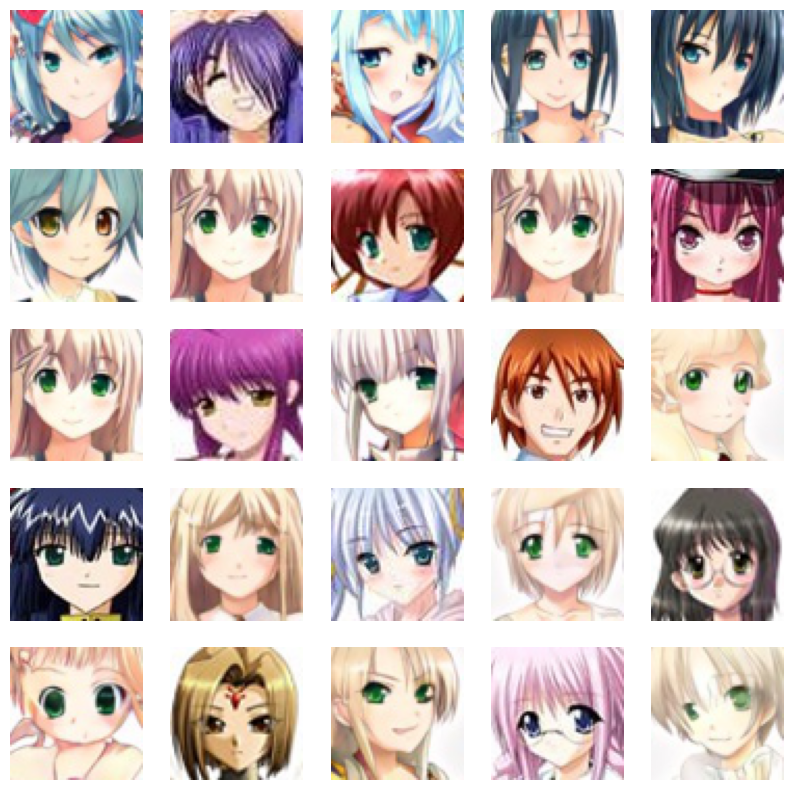

In [6]:
# Load the dataset
dataset_path = r".\images"  # Replace with the actual path to your dataset
images = []

for img_name in os.listdir(dataset_path):
    img_path = os.path.join(dataset_path, img_name)
    img = Image.open(img_path).resize((64, 64))  # Resize images to 64x64
    img = np.array(img) / 255.0  # Normalize pixel values to [0, 1]
    images.append(img)

images = np.array(images)

# Visualize some images
plt.figure(figsize=(10, 10))
for i in range(25):
    plt.subplot(5, 5, i+1)
    plt.imshow(images[i])
    plt.axis('off')
plt.show()

 Explanation: We load the images from the dataset, resize them to 64x64 pixels, and normalize the pixel values to the range [0, 1]. We then visualize some of the images to ensure they are loaded correctly.

### Step 3: Building the Generator
The generator creates new images from random noise.

In [7]:
def build_generator():
    model = tf.keras.Sequential()

    # First layer
    model.add(layers.Dense(8*8*256, use_bias=False, input_shape=(100,)))
    model.add(layers.BatchNormalization())
    model.add(layers.LeakyReLU())

    # Reshape to 8x8x256
    model.add(layers.Reshape((8, 8, 256)))

    # Upsample to 16x16
    model.add(layers.Conv2DTranspose(128, (5, 5), strides=(2, 2), padding='same', use_bias=False))
    model.add(layers.BatchNormalization())
    model.add(layers.LeakyReLU())

    # Upsample to 32x32
    model.add(layers.Conv2DTranspose(64, (5, 5), strides=(2, 2), padding='same', use_bias=False))
    model.add(layers.BatchNormalization())
    model.add(layers.LeakyReLU())

    # Upsample to 64x64
    model.add(layers.Conv2DTranspose(3, (5, 5), strides=(2, 2), padding='same', use_bias=False, activation='tanh'))

    return model

generator = build_generator()

Explanation: The generator takes a 100-dimensional noise vector as input and upsamples it through a series of transposed convolutional layers to produce a 64x64 RGB image.

### Step 4: Building the Discriminator
The discriminator distinguishes between real and fake images.

In [8]:
def build_discriminator():
    model = tf.keras.Sequential()

    # Input layer
    model.add(layers.Conv2D(64, (5, 5), strides=(2, 2), padding='same', input_shape=[64, 64, 3]))
    model.add(layers.LeakyReLU())
    model.add(layers.Dropout(0.3))

    # Downsample to 32x32
    model.add(layers.Conv2D(128, (5, 5), strides=(2, 2), padding='same'))
    model.add(layers.LeakyReLU())
    model.add(layers.Dropout(0.3))

    # Downsample to 16x16
    model.add(layers.Conv2D(256, (5, 5), strides=(2, 2), padding='same'))
    model.add(layers.LeakyReLU())
    model.add(layers.Dropout(0.3))

    # Flatten and output
    model.add(layers.Flatten())
    model.add(layers.Dense(1))

    return model

discriminator = build_discriminator()

Explanation: The discriminator takes a 64x64 RGB image as input and downsamples it through a series of convolutional layers to produce a single output value indicating whether the image is real or fake.

### Step 5: Defining the Loss Functions and Optimizers
We define the loss functions and optimizers for both the generator and discriminator.

In [9]:
cross_entropy = tf.keras.losses.BinaryCrossentropy(from_logits=True)

def discriminator_loss(real_output, fake_output):
    real_loss = cross_entropy(tf.ones_like(real_output), real_output)
    fake_loss = cross_entropy(tf.zeros_like(fake_output), fake_output)
    total_loss = real_loss + fake_loss
    return total_loss

def generator_loss(fake_output):
    return cross_entropy(tf.ones_like(fake_output), fake_output)

generator_optimizer = tf.keras.optimizers.Adam(1e-4)
discriminator_optimizer = tf.keras.optimizers.Adam(1e-4)

Explanation: We use binary cross-entropy loss for both the generator and discriminator. The generator tries to minimize the loss, while the discriminator tries to maximize it.

### Step 6: Training the GAN
Finally, we train the GAN.

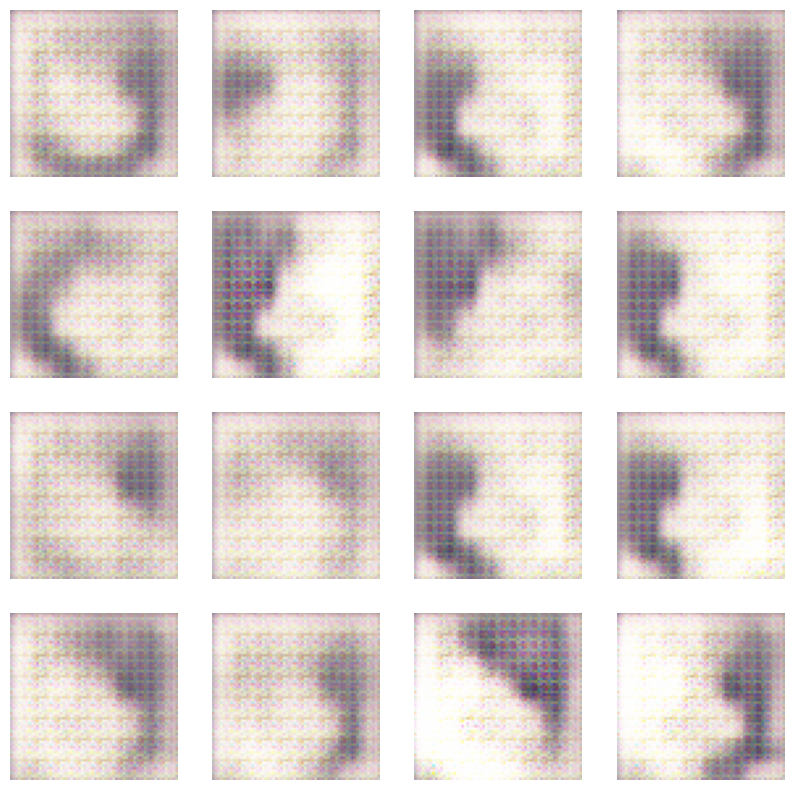

Epoch 1 took 1237.89 seconds


In [ ]:
@tf.function
def train_step(images):
    noise = tf.random.normal([BATCH_SIZE, 100])

    with tf.GradientTape() as gen_tape, tf.GradientTape() as disc_tape:
        generated_images = generator(noise, training=True)

        real_output = discriminator(images, training=True)
        fake_output = discriminator(generated_images, training=True)

        gen_loss = generator_loss(fake_output)
        disc_loss = discriminator_loss(real_output, fake_output)

    gradients_of_generator = gen_tape.gradient(gen_loss, generator.trainable_variables)
    gradients_of_discriminator = disc_tape.gradient(disc_loss, discriminator.trainable_variables)

    generator_optimizer.apply_gradients(zip(gradients_of_generator, generator.trainable_variables))
    discriminator_optimizer.apply_gradients(zip(gradients_of_discriminator, discriminator.trainable_variables))

def train(dataset, epochs):
    for epoch in range(epochs):
        start = time.time()

        for image_batch in dataset:
            train_step(image_batch)

        # Generate and save images every epoch
        generate_and_save_images(generator, epoch + 1, tf.random.normal([16, 100]))

        print(f'Epoch {epoch + 1} took {time.time() - start:.2f} seconds')

def generate_and_save_images(model, epoch, test_input):
    predictions = model(test_input, training=False)
    plt.figure(figsize=(10, 10))

    for i in range(predictions.shape[0]):
        plt.subplot(4, 4, i+1)
        plt.imshow(predictions[i, :, :, :] * 0.5 + 0.5)  # Rescale to [0, 1]
        plt.axis('off')

    plt.savefig(f'image_at_epoch_{epoch:04d}.png')
    plt.show()

# Train the GAN
BATCH_SIZE = 256
EPOCHS = 50
train_dataset = tf.data.Dataset.from_tensor_slices(images).shuffle(60000).batch(BATCH_SIZE)
train(train_dataset, EPOCHS)

Explanation: We define the training loop where the generator and discriminator are trained alternately. After each epoch, we generate and save some images to visualize the progress of the generator.

In [1]:
# Generate and display images
def generate_and_display_images(model, num_images=16):
    noise = tf.random.normal([num_images, 100])
    generated_images = model(noise, training=False)

    plt.figure(figsize=(10, 10))
    for i in range(generated_images.shape[0]):
        plt.subplot(4, 4, i+1)
        plt.imshow(generated_images[i, :, :, :] * 0.5 + 0.5)  # Rescale to [0, 1]
        plt.axis('off')
    plt.show()

# Display generated images
generate_and_display_images(generator)

NameError: name 'generator' is not defined

In [ ]:
# Install the required library
!pip install scikit-learn

from sklearn.metrics.pairwise import cosine_similarity

def calculate_precision_recall(real_images, generated_images, k=3):
    real_features = inception_model_fid(real_images)
    generated_features = inception_model_fid(generated_images)

    precision_scores = []
    recall_scores = []

    for gen_feat in generated_features:
        distances = cosine_similarity([gen_feat], real_features)
        precision_scores.append(np.mean(np.sort(distances[0])[-k:]))

    for real_feat in real_features:
        distances = cosine_similarity([real_feat], generated_features)
        recall_scores.append(np.mean(np.sort(distances[0])[-k:]))

    precision = np.mean(precision_scores)
    recall = np.mean(recall_scores)

    return precision, recall

# Calculate Precision and Recall
precision, recall = calculate_precision_recall(real_images_resized, generated_images_resized)
print(f"Precision: {precision}, Recall: {recall}")

In [ ]:
# Generate new anime faces
num_images = 16
noise = tf.random.normal([num_images, 100])
generated_images = generator(noise, training=False)

# Display the generated images
plt.figure(figsize=(10, 10))
for i in range(generated_images.shape[0]):
    plt.subplot(4, 4, i+1)
    plt.imshow(generated_images[i, :, :, :] * 0.5 + 0.5)  # Rescale to [0, 1]
    plt.axis('off')
plt.show()

### Step 7: Conclusion
After training, you can compare your GAN model with StyleGAN and StyleGAN2, as mentioned in the project requirements. You can also explore transfer learning by fine-tuning pre-trained models like StyleGAN on your dataset.